# Compare protein prizes from the Olsen 2006 data and our EGFR data - February 17, 2017
Ignore the specific phosphorylation sites and the direction of the change for now.  Olsen 2006 prizes are based on absolute value of log fold changes.  Ale's prizes are based on the Tukey HSD test.

## Initializations

In [1]:
%pylab inline
import os
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

# Our EGFR data from Ale's lab
# Uses an older TPS format
ale_prize_file = os.path.join('..','..','phosphorylation-data-sets','McKenna2014','McKenna2014_aggregated_replicateABC_tukey_firstprev_proteinPrizes_firstProtein.txt')

# Olsen 2006 results
olsen_prize_file = os.path.join('..','..','phosphorylation-data-sets','Olsen2006','olsen2006-protein-prizes-foldchange-2-cleaned.txt')

out_dir = os.path.join('..','..','evaluation','2017-02-17-egfr-prize-comparison')
if not os.path.exists(out_dir):
    os.makedirs(out_dir)
    print('Created {}'.format(out_dir))

Populating the interactive namespace from numpy and matplotlib


## Helper function to load prizes
Include pseudonodes

In [2]:
def load_prizes(prize_file):
    nodes = list()
    prizes = list()

    with open(prize_file) as prize_f:
        for line in prize_f:
            # Prot1 \t Prize
            parts = line.strip().split('\t')
            assert len(parts) == 2, 'Expected protein and prize'
            nodes.append(parts[0])
            prizes.append(float(parts[1]))
    
    # Create data frame
    df = pd.DataFrame({'Nodes':nodes, 'Prizes':prizes})
    print 'Loaded %d prizes' % (len(df))
    return df

## Load the prize files

In [3]:
print("Ale's data")
ale_prize_df = load_prizes(ale_prize_file)
assert len(ale_prize_df) == 701
print

print('Olsen 2006 data')
olsen_prize_df = load_prizes(olsen_prize_file)
assert len(olsen_prize_df) == 647

Ale's data
Loaded 701 prizes

Olsen 2006 data
Loaded 647 prizes


## Merge the dataframes and plot the prizes for the common proteins
First only consider common proteins and drop the rest

In [4]:
# Keep only the nodes in both data frames
both_inner_prize_df = pd.merge(ale_prize_df, olsen_prize_df, how='inner', on=['Nodes'])
print('{} common prizes'.format(len(both_inner_prize_df)))

both_inner_prize_df = both_inner_prize_df.rename(columns={'Prizes_x':'Ale prize', 'Prizes_y':'Olsen 2006 prize'})
both_inner_prize_df.head()

159 common prizes


,Nodes,Ale prize,Olsen 2006 prize
0,ACACA_HUMAN,1.413802,2.183222
1,ACINU_HUMAN,5.059743,3.257298
2,ACK1_HUMAN,4.634804,2.469485
3,AHNK_HUMAN,1.038469,4.892545
4,AKA11_HUMAN,0.927726,2.321928


Pearson correlation: 0.338181664372


C:\Program Files\Anaconda\lib\site-packages\matplotlib\collections.py:590: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == str('face'):


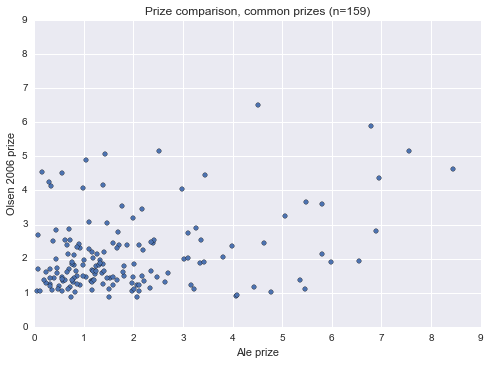

In [5]:
title_str = 'Prize comparison, common prizes (n={})'.format(len(both_inner_prize_df))
both_inner_prize_df.plot(x='Ale prize', y='Olsen 2006 prize', kind='scatter', title=title_str);
axis([0,9,0,9]);
print('Pearson correlation: {}'.format(pearsonr(both_inner_prize_df['Ale prize'], both_inner_prize_df['Olsen 2006 prize'])[0]))
savefig(os.path.join(out_dir, 'common_prize_comparison.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'common_prize_comparison.svg'), bbox_inches='tight')

## Merge the dataframes and plot the prizes for the common proteins
Now assign a prize of 0 to all prizes unique to one dataset.  This will overweight the 0s in the correlation because those are individual peptides, which may map to a smaller number of unique proteins.  To correct that, also consider a version where all 180 pseudonodes have been removed.  Removing pseudonodes does not have an notable effect.

Some proteins with very large prizes on one dataset are not observed in the other.

In [6]:
both_outer_prize_df = pd.merge(ale_prize_df, olsen_prize_df, how='outer', on=['Nodes'])
print('{} unique prizes'.format(len(both_outer_prize_df)))

both_outer_prize_df = both_outer_prize_df.rename(columns={'Prizes_x':'Ale prize', 'Prizes_y':'Olsen 2006 prize'})
both_outer_prize_df = both_outer_prize_df.fillna(value=0)
both_outer_prize_df.head()

1189 unique prizes


,Nodes,Ale prize,Olsen 2006 prize
0,1433Z_HUMAN,1.041379,0.0
1,41_HUMAN,3.389113,0.0
2,4ET_HUMAN,2.569974,0.0
3,A8K1N6_HUMAN,1.948222,0.0
4,A9CQZ4_HUMAN,0.421461,0.0


Pearson correlation: -0.229514395218


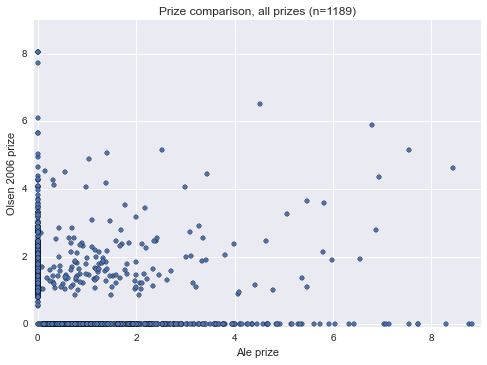

In [7]:
title_str = 'Prize comparison, all prizes (n={})'.format(len(both_outer_prize_df))
both_outer_prize_df.plot(x='Ale prize', y='Olsen 2006 prize', kind='scatter', title=title_str);
axis([-0.07,9,-0.07,9]);
print('Pearson correlation: {}'.format(pearsonr(both_outer_prize_df['Ale prize'], both_outer_prize_df['Olsen 2006 prize'])[0]))
savefig(os.path.join(out_dir, 'all_prize_comparison.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'all_prize_comparison.svg'), bbox_inches='tight')

In [8]:
both_no_pseudo_prize_df = both_outer_prize_df[np.logical_not(both_outer_prize_df['Nodes'].str.contains('PSEUDONODE'))]
print('{} unique prizes after removing PSEUDONODEs'.format(len(both_no_pseudo_prize_df)))
both_no_pseudo_prize_df.head()

1009 unique prizes after removing PSEUDONODEs


,Nodes,Ale prize,Olsen 2006 prize
0,1433Z_HUMAN,1.041379,0.0
1,41_HUMAN,3.389113,0.0
2,4ET_HUMAN,2.569974,0.0
3,A8K1N6_HUMAN,1.948222,0.0
4,A9CQZ4_HUMAN,0.421461,0.0


Pearson correlation: -0.183417830898


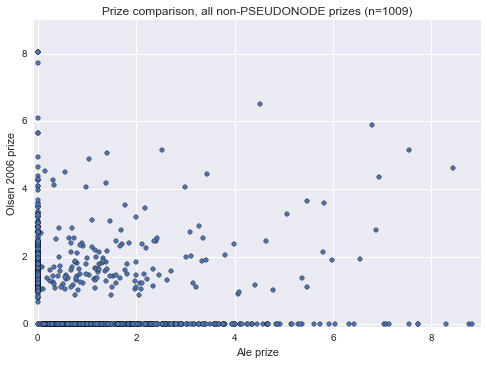

In [9]:
title_str = 'Prize comparison, all non-PSEUDONODE prizes (n={})'.format(len(both_no_pseudo_prize_df))
both_no_pseudo_prize_df.plot(x='Ale prize', y='Olsen 2006 prize', kind='scatter', title=title_str);
axis([-0.07,9,-0.07,9]);
print('Pearson correlation: {}'.format(pearsonr(both_no_pseudo_prize_df['Ale prize'], both_no_pseudo_prize_df['Olsen 2006 prize'])[0]))
savefig(os.path.join(out_dir, 'all_protein_prize_comparison.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'all_protein_prize_comparison.svg'), bbox_inches='tight')